In [1]:
# multimodal_price_regressor.py
import os, math, random, time
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sentence_transformers import SentenceTransformer
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms
import clip  # pip install git+https://github.com/openai/CLIP.git
from tqdm import tqdm

device = "cuda:1" if torch.cuda.is_available() else "cpu"
embeddings_folder = 'embeddings'
os.makedirs(embeddings_folder, exist_ok=True)

In [2]:
# -------------------------
# Utility: SMAPE metric
# -------------------------
def smape(y_true, y_pred, eps=1e-8):
    num = np.abs(y_pred - y_true)
    den = (np.abs(y_true) + np.abs(y_pred)) / 2.0 + eps
    return np.mean(num / den)

def smape_torch(y_true, y_pred, eps=1e-8):
    num = (y_pred - y_true).abs()
    den = (y_true.abs() + y_pred.abs()) / 2 + eps
    return (num / den).mean()

In [3]:
# -------------------------
# 1) Load CSV and create stratified val
# -------------------------
df = pd.read_csv('../clean_data/train_cleaned.csv')  # adjust path
df["Description"] = df["Description"].fillna("")
df["Item Name"] = df["Item Name"].fillna("")
df["Unit"] = df["Unit"].fillna("unknown")
df["Value"] = df["Value"].fillna(1.0)
df["price"] = df["price"].astype(float)



# # Quick preprocessing: fill nans
# df['catalog_content'] = df['catalog_content'].fillna('')

# create log price bins for stratified split
df['log_price'] = np.log1p(df['price'])
df['price_bin'] = pd.qcut(df['log_price'], 10, labels=False, duplicates='drop')

train_df, val_df = train_test_split(df, test_size=0.1, random_state=42, stratify=df['price_bin'])
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print(f"Train: {len(train_df)}, Val: {len(val_df)}")

Train: 67499, Val: 7500


## Textual Embedding

In [9]:
# -------------------------
# 2) Text & numeric feature extractor
# -------------------------
# Load a sentence-transformer model (fast & accurate)
text_model = SentenceTransformer('all-mpnet-base-v2')  # 768-d

for df_ in [train_df, val_df]:
    df_['desc_len'] = df_['Description'].apply(lambda x: len(x))
    df_['has_image'] = df_['sample_id'].apply(lambda sid: os.path.exists(f'images/train/{sid}.jpg')).astype(float)

# Standardize numeric features
scaler = StandardScaler()
num_cols = ['Value', 'desc_len', 'has_image']
scaler.fit(train_df[num_cols])
train_num = scaler.transform(train_df[num_cols])
val_num = scaler.transform(val_df[num_cols])

# -------------------------
# 3) Precompute text embeddings (to speed up training)
# -------------------------
def compute_text_embeddings(df, batch_size=128):
    texts = (df["Item Name"].astype(str) + " " + df["Description"].astype(str)).tolist()
    return text_model.encode(
        texts, batch_size=batch_size, show_progress_bar=True, convert_to_numpy=True
    )

print("Computing text embeddings...")
train_text_emb = compute_text_embeddings(train_df)
val_text_emb = compute_text_embeddings(val_df)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Computing text embeddings...


Batches:   0%|          | 0/528 [00:00<?, ?it/s]

Batches:   0%|          | 0/59 [00:00<?, ?it/s]

In [10]:
# ==============================
# Numeric + categorical features
# ==============================
# Encode Unit
le_unit = LabelEncoder()
le_unit.fit(df["Unit"].astype(str))
train_unit = le_unit.transform(train_df["Unit"].astype(str))
val_unit = le_unit.transform(val_df["Unit"].astype(str))

train_numeric = np.stack(
    [
        train_df["Value"].values.astype(float),
        train_unit.astype(float)
    ],
    axis=1,
)
val_numeric = np.stack(
    [
        val_df["Value"].values.astype(float),
        val_unit.astype(float)
    ],
    axis=1,
)

scaler = StandardScaler()
train_num_scaled = scaler.fit_transform(train_numeric)
val_num_scaled = scaler.transform(val_numeric)

## Image Embedding

In [11]:
# -------------------------
# 4) CLIP image encoder (pretrained)
# -------------------------
clip_model, clip_preprocess = clip.load("ViT-B/32", device=device, jit=False)  # ViT-B/32 is compact

# helper to load image -> embed
def image_to_emb(sample_id, model=clip_model, preprocess=clip_preprocess, device=device):
    img_path = f'../images/train/{sample_id}.jpg'
    if not os.path.exists(img_path):
        # fallback blank vector
        return np.zeros(model.visual.output_dim)
    img = Image.open(img_path).convert('RGB')
    img_t = preprocess(img).unsqueeze(0).to(device)
    with torch.no_grad():
        im_emb = model.encode_image(img_t)
        im_emb = im_emb.cpu().numpy().reshape(-1)
    return im_emb

# Precompute image embeddings (caching recommended)
def batch_image_embs(df_):
    embs = []
    for sid in tqdm(df_['sample_id'].tolist(), desc='images'):
        embs.append(image_to_emb(sid))
    return np.vstack(embs)

print("Computing image embeddings (can be slow)...")
train_img_emb = batch_image_embs(train_df)
val_img_emb = batch_image_embs(val_df)


Computing image embeddings (can be slow)...


images: 100%|██████████| 7500/7500 [03:24<00:00, 36.68it/s]


In [13]:
# save embeddings to disk (optional)
np.save(os.path.join(embeddings_folder, 'train_text_emb.npy'), train_text_emb)
np.save(os.path.join(embeddings_folder, 'val_text_emb.npy'), val_text_emb)
np.save(os.path.join(embeddings_folder, 'train_img_emb.npy'), train_img_emb)
np.save(os.path.join(embeddings_folder, 'val_img_emb.npy'), val_img_emb)
np.save(os.path.join(embeddings_folder, 'train_num_scaled.npy'), train_num_scaled)
np.save(os.path.join(embeddings_folder, 'val_num_scaled.npy'), val_num_scaled)

## Load Embeddings

In [22]:
# load all the data
train_text_emb = np.load(os.path.join(embeddings_folder, 'train_text_emb.npy'))
val_text_emb = np.load(os.path.join(embeddings_folder, 'val_text_emb.npy'))
train_img_emb = np.load(os.path.join(embeddings_folder, 'train_img_emb.npy'))
val_img_emb = np.load(os.path.join(embeddings_folder, 'val_img_emb.npy'))
train_num_scaled = np.load(os.path.join(embeddings_folder, 'train_num_scaled.npy'))
val_num_scaled = np.load(os.path.join(embeddings_folder, 'val_num_scaled.npy'))

In [23]:
clip_model, clip_preprocess = clip.load("ViT-B/32", device=device, jit=False)  # ViT-B/32 is compact

In [24]:
# -------------------------
# 5) Dataset + DataLoader
# -------------------------
class MultimodalDataset(Dataset):
    def __init__(self, text_embs, img_embs, num_feats, prices):
        self.text = text_embs.astype(np.float32)
        self.img = img_embs.astype(np.float32)
        self.num = num_feats.astype(np.float32)
        self.y = prices.astype(np.float32)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return {'text': self.text[idx], 'img': self.img[idx], 'num': self.num[idx], 'y': self.y[idx]}

train_ds = MultimodalDataset(train_text_emb, train_img_emb, train_num_scaled, np.log1p(train_df['price'].values))
val_ds = MultimodalDataset(val_text_emb, val_img_emb, val_num_scaled, np.log1p(val_df['price'].values))

train_loader = DataLoader(train_ds, batch_size=1000, shuffle=True, num_workers=4)
val_loader = DataLoader(val_ds, batch_size=1000, shuffle=False, num_workers=2)

In [25]:
# -------------------------
# 6) Fusion model (simple MLP)
# -------------------------
class FusionRegressor(nn.Module):
    def __init__(self, text_dim=768, img_dim=512, num_dim=3, hidden=1024):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(text_dim + img_dim + num_dim, hidden),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden, hidden//2),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden//2, 1)
        )
    def forward(self, text, img, num):
        x = torch.cat([text, img, num], dim=1)
        return self.fc(x).squeeze(1)

# detect image dimension from clip model:
img_dim = clip_model.visual.output_dim
model = FusionRegressor(text_dim=train_text_emb.shape[1], img_dim=img_dim, num_dim=train_num_scaled.shape[1], hidden=1024)
model = model.to(device)

# # print model summary
# from torchsummary import summary
# summary(model, [(train_text_emb.shape[1],), (img_dim,), (train_num_scaled.shape[1],)], device=device)

In [26]:
# -------------------------
# 7) Training loop (MAE loss on log price), report SMAPE
# -------------------------
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
criterion = nn.L1Loss()  # MAE on log price
epochs = 100

plot_train_losses = []
plot_val_losses = []
plot_val_smapes = []

for epoch in range(epochs):
    model.train()
    train_losses = []
    for batch in train_loader:
        text = torch.tensor(batch['text']).to(device)
        img = torch.tensor(batch['img']).to(device)
        num = torch.tensor(batch['num']).to(device)
        y = torch.tensor(batch['y']).to(device)
        preds = model(text, img, num)
        loss = criterion(preds, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())
    # validation
    model.eval()
    ys = []
    yps = []
    val_losses = []
    with torch.no_grad():
        for batch in val_loader:
            text = torch.tensor(batch['text']).to(device)
            img = torch.tensor(batch['img']).to(device)
            num = torch.tensor(batch['num']).to(device)
            y = torch.tensor(batch['y']).to(device)
            pred = model(text, img, num)
            loss = criterion(pred, y)
            ys.append(y.cpu().numpy())
            yps.append(pred.cpu().numpy())
            val_losses.append(loss.item())
    ys = np.concatenate(ys)
    yps = np.concatenate(yps)
    # convert back from log1p
    y_true = np.expm1(ys)
    y_pred = np.expm1(yps)
    val_smape = smape(y_true, y_pred)
    plot_train_losses.append(np.mean(train_losses))
    plot_val_losses.append(np.mean(val_losses))
    plot_val_smapes.append(val_smape)
    if (epoch+1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch+1}/{epochs} train_loss={np.mean(train_losses):.4f} val_loss={np.mean(val_losses):.4f} val_smape={val_smape:.4f}")


/tmp/ipykernel_2043775/1138414136.py:16: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  text = torch.tensor(batch['text']).to(device)
/tmp/ipykernel_2043775/1138414136.py:17: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  img = torch.tensor(batch['img']).to(device)
/tmp/ipykernel_2043775/1138414136.py:18: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  num = torch.tensor(batch['num']).to(device)
/tmp/ipykernel_2043775/1138414136.py:19: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sour

Epoch 1/100 train_loss=1.1265 val_loss=0.6835 val_smape=0.6614


/tmp/ipykernel_2043775/1138414136.py:33: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  text = torch.tensor(batch['text']).to(device)
/tmp/ipykernel_2043775/1138414136.py:34: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  img = torch.tensor(batch['img']).to(device)
/tmp/ipykernel_2043775/1138414136.py:35: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  num = torch.tensor(batch['num']).to(device)
/tmp/ipykernel_2043775/1138414136.py:36: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sour

Epoch 10/100 train_loss=0.5436 val_loss=0.5617 val_smape=0.5580
Epoch 20/100 train_loss=0.4694 val_loss=0.5418 val_smape=0.5397
Epoch 30/100 train_loss=0.4186 val_loss=0.5344 val_smape=0.5332
Epoch 40/100 train_loss=0.3774 val_loss=0.5354 val_smape=0.5342
Epoch 50/100 train_loss=0.3483 val_loss=0.5370 val_smape=0.5361
Epoch 60/100 train_loss=0.3240 val_loss=0.5375 val_smape=0.5363
Epoch 70/100 train_loss=0.3040 val_loss=0.5366 val_smape=0.5349
Epoch 80/100 train_loss=0.2919 val_loss=0.5426 val_smape=0.5399
Epoch 90/100 train_loss=0.2740 val_loss=0.5370 val_smape=0.5360
Epoch 100/100 train_loss=0.2641 val_loss=0.5375 val_smape=0.5364


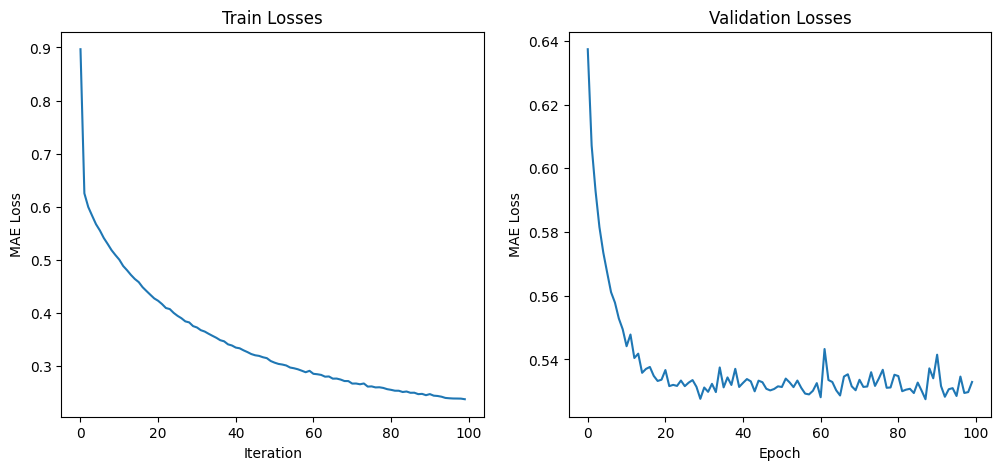

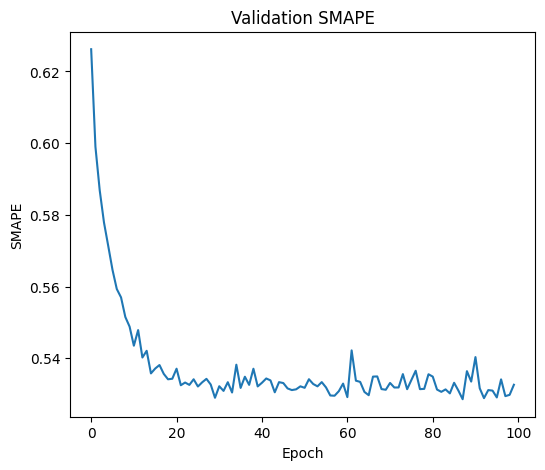

In [21]:
# plot training curves
import matplotlib.pyplot as plt
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(plot_train_losses)
plt.title('Train Losses')
plt.xlabel('Iteration')
plt.ylabel('MAE Loss')
plt.subplot(1,2,2)
plt.plot(plot_val_losses)
plt.title('Validation Losses')
plt.xlabel('Epoch')
plt.ylabel('MAE Loss')
plt.show()

plt.figure(figsize=(6,5))
plt.plot(plot_val_smapes)
plt.title('Validation SMAPE')
plt.xlabel('Epoch')
plt.ylabel('SMAPE')
plt.show()

In [ ]:

# # Save model
# torch.save({
#     'model_state_dict': model.state_dict(),
#     'scaler': scaler,
#     'text_model_name': 'all-mpnet-base-v2'
# }, 'fusion_regressor.pth')
